In [1]:
import numpy as np

import smplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import astropy.units as u
from astropy.constants import L_sun
from astropy.cosmology import Planck18, z_at_value

import fsps
from sedpy.observate import getSED, load_filters


In [2]:
REFERENCE_REDSHIFT = 5.0
DUST_VECTOR_AV = 1.0

MODEL_CONFIGS = {
    "old_quiescent": {
        "label": "Old quiescent",
        "stellar_mass_msun": 1e11,
        "logzsol": 0.2,
        "age_at_reference_redshift_gyr": 1.0,
        "tau_gyr": 0.1,
        "dust2": 0.0,
        "imf_type": 2,
    },
    "young_quiescent": {
        "label": "Young quiescent",
        "stellar_mass_msun": 1e10,
        "logzsol": 0.0,
        "age_at_reference_redshift_gyr": 0.5,
        "tau_gyr": 0.06,
        "dust2": 0.0,
        "imf_type": 2,
    },
    "mini_quenched": {
        "label": "Mini-quenched",
        "stellar_mass_msun": 1e9,
        "logzsol": -0.5,
        "age_at_reference_redshift_gyr": 0.1,
        "tau_gyr": 0.03,
        "dust2": 0.0,
        "imf_type": 2,
    },
}

FILTER_NAMES = ["jwst_f150w", "jwst_f150w2", "jwst_f277w", "jwst_f444w"]
FILTER_LABELS = ["F150W", "F150W2", "F277W", "F444W"]
TRACK_REDSHIFTS = np.arange(4.0, 6.1, 0.1)
EXAMPLE_REDSHIFTS = [4.0, 5.0, 6.0]
COLOUR_MODES = {
    "f150w": {
        "label": "F150W colours",
        "x_label": "F150W - F277W",
        "y_label": "F277W - F444W",
        "blue_filter": "F150W",
    },
    "f150w2": {
        "label": "F150W2 colours",
        "x_label": "F150W2 - F277W",
        "y_label": "F277W - F444W",
        "blue_filter": "F150W2",
    },
}
LONG24_SHORT_WEDGE = {
    "intercept_a": 1.5,
    "slope_a": 6.25,
    "intercept_b": 1.5,
    "slope_b": -0.5,
    "slope_c": 2.8,
}
LONG24_LONG_WEDGE = {
    "intercept_a": 1.5,
    "slope_a": 6.25,
    "intercept_b": 1.15,
    "slope_b": -0.5,
    "slope_c": 2.8,
}
PLOT_STYLES = {
    "old_quiescent": {"color": "crimson", "marker": "o"},
    "young_quiescent": {"color": "darkorange", "marker": "s"},
    "mini_quenched": {"color": "dodgerblue", "marker": "^"},
}

SED_POINT_LABELS = ["F150W", "F150W2", "F277W", "F444W"]


In [3]:
def initialise_fsps_population(imf_type=2):
    """Initialise a delayed-tau FSPS population."""

    return fsps.StellarPopulation(zcontinuous=1, sfh=4, imf_type=imf_type, dust_type=2)


def calculate_population_age_gyr(z_obs, z_form):
    """Return the stellar population age at `z_obs` for a given formation redshift."""

    age_gyr = (Planck18.age(z_obs) - Planck18.age(z_form)).value
    if age_gyr <= 0:
        raise ValueError("Formation redshift must be larger than the observed redshift")
    return age_gyr


def calculate_formation_redshift(z_obs, age_gyr):
    """Return the formation redshift that gives a target age at `z_obs`."""

    formation_universe_age = (Planck18.age(z_obs) - age_gyr * u.Gyr)
    if formation_universe_age <= 0 * u.Gyr:
        raise ValueError("Requested population age is older than the Universe at the observed redshift")
    return float(z_at_value(Planck18.age, formation_universe_age, zmin=z_obs + 1e-3, zmax=100.0))


def calibrate_model_config(model_config):
    """Attach `z_form` to a model config and verify the reference age calibration."""

    calibrated_config = dict(model_config)
    calibrated_config["reference_redshift"] = REFERENCE_REDSHIFT
    calibrated_config["formation_redshift"] = calculate_formation_redshift(
        calibrated_config["reference_redshift"],
        calibrated_config["age_at_reference_redshift_gyr"],
    )

    recovered_age_gyr = calculate_population_age_gyr(
        calibrated_config["reference_redshift"],
        calibrated_config["formation_redshift"],
    )
    if not np.isclose(recovered_age_gyr, calibrated_config["age_at_reference_redshift_gyr"], rtol=0.0, atol=1e-4):
        raise ValueError("Recovered age at the reference redshift does not match the requested calibration")

    return calibrated_config


def convert_av_to_dust2(av):
    """Approximate conversion from A_V to the FSPS `dust2` screen parameter."""

    return av / 1.086


def select_valid_redshifts(redshift_grid, z_form):
    """Keep only the observed redshifts that occur after formation."""

    valid_redshifts = np.asarray(redshift_grid)[np.asarray(redshift_grid) < z_form]
    if valid_redshifts.size == 0:
        raise ValueError("No valid observed redshifts remain once `z_obs < z_form` is enforced")
    return valid_redshifts


def long24_short_wedge_lines(x_values):
    """Return the Long+24 short-wedge boundaries in the x-y plane.

    The published selection is defined for x = F150W - F277W and
    y = F277W - F444W.
    """

    x_values = np.asarray(x_values)
    y_a = (x_values - LONG24_SHORT_WEDGE["intercept_a"]) / LONG24_SHORT_WEDGE["slope_a"]
    y_b = (LONG24_SHORT_WEDGE["intercept_b"] - x_values) / LONG24_SHORT_WEDGE["slope_b"]
    y_c = x_values / LONG24_SHORT_WEDGE["slope_c"]

    return y_a, y_b, y_c


def passes_long24_short_wedge(x_values, y_values):
    """Evaluate the published Long+24 short wedge."""

    x_values = np.asarray(x_values)
    y_values = np.asarray(y_values)

    cond_a = x_values < LONG24_SHORT_WEDGE["intercept_a"] + LONG24_SHORT_WEDGE["slope_a"] * y_values
    cond_b = x_values > LONG24_SHORT_WEDGE["intercept_b"] + LONG24_SHORT_WEDGE["slope_b"] * y_values
    cond_c = x_values > LONG24_SHORT_WEDGE["slope_c"] * y_values

    return cond_a & cond_b & cond_c


def build_long24_wedge_polygon(wedge_config, x_min=0.0, x_max=2.8, y_min=-0.2, y_max=1.2):
    """Build a closed Long+24 wedge clipped to the plotting window."""

    y_values = np.linspace(max(0.0, y_min), y_max, 800)
    lower_b = wedge_config["intercept_b"] + wedge_config["slope_b"] * y_values
    lower_c = wedge_config["slope_c"] * y_values
    upper_a = wedge_config["intercept_a"] + wedge_config["slope_a"] * y_values

    x_lower = np.maximum.reduce([lower_b, lower_c, np.full_like(y_values, x_min)])
    x_upper = np.minimum(upper_a, x_max)
    valid = x_upper >= x_lower

    if not np.any(valid):
        return None

    x_poly = np.concatenate([x_upper[valid], x_lower[valid][::-1], [x_upper[valid][0]]])
    y_poly = np.concatenate([y_values[valid], y_values[valid][::-1], [y_values[valid][0]]])

    return x_poly, y_poly


def plot_long24_wedge(ax, wedge_config, x_min=0.0, x_max=2.8, y_min=-0.2, y_max=1.2, label_prefix="Long+24", lw=1.2, ls="-"):
    """Plot a clipped Long+24 wedge on an axis."""

    polygon = build_long24_wedge_polygon(wedge_config, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max)
    if polygon is None:
        return None

    x_poly, y_poly = polygon
    ax.plot(x_poly, y_poly, color="black", lw=lw, ls=ls, label=label_prefix)
    ax.fill(x_poly, y_poly, facecolor="none", edgecolor="none")

    return x_poly, y_poly

def convert_maggies_to_flambda_cgs(maggies, wave_aa):
    """Convert maggies to cgs f_lambda at the filter effective wavelengths."""

    f_nu = np.asarray(maggies) * 3631.0 * u.Jy
    return f_nu.to(u.erg / (u.s * u.cm**2 * u.AA), equivalencies=u.spectral_density(np.asarray(wave_aa) * u.AA)).value


def build_mock_sed(sp, z_obs, model_config, filters, filter_labels, dust2=None):
    """Build an observed-frame delayed-tau mock SED and JWST photometry.

    Parameters
    ----------
    sp : fsps.StellarPopulation
        FSPS stellar population object.
    z_obs : float
        Observed redshift.
    model_config : dict
        Model choices for mass, metallicity, age calibration, formation redshift,
        tau and dust.
    filters : list
        Loaded `sedpy` filters.
    filter_labels : list
        Short labels for the loaded filters.
    dust2 : float or None, optional
        Override the default dust2 value.

    Returns
    -------
    products : dict
        Dictionary containing the observed-frame spectrum, filter photometry,
        colours and a few summary quantities.
    """

    dust2_use = model_config["dust2"] if dust2 is None else dust2
    z_form = model_config["formation_redshift"]
    if z_form <= z_obs:
        raise ValueError("Formation redshift must be larger than the observed redshift")

    age_gyr = calculate_population_age_gyr(z_obs, z_form)
    universe_age_gyr = Planck18.age(z_obs).value

    sp.params["logzsol"] = model_config["logzsol"]
    sp.params["tau"] = model_config["tau_gyr"]
    sp.params["dust2"] = dust2_use

    wave_rest_aa, lum_rest_lsun_per_aa = sp.get_spectrum(tage=age_gyr, peraa=True)

    formed_mass_msun = model_config["stellar_mass_msun"] / sp.stellar_mass
    lum_rest_cgs_per_aa = lum_rest_lsun_per_aa * formed_mass_msun * L_sun.to("erg / s").value

    wave_obs_aa = wave_rest_aa * (1.0 + z_obs)
    lum_distance_cm = Planck18.luminosity_distance(z_obs).to("cm").value
    flux_obs_cgs_per_aa = lum_rest_cgs_per_aa / (4.0 * np.pi * lum_distance_cm**2 * (1.0 + z_obs))

    sed_abmag = np.asarray(getSED(wave_obs_aa, flux_obs_cgs_per_aa, filters))
    sed_maggies = np.asarray(getSED(wave_obs_aa, flux_obs_cgs_per_aa, filters, linear_flux=True))

    filter_wave_aa = np.array([band.wave_effective for band in filters])
    sed_flambda_cgs = convert_maggies_to_flambda_cgs(sed_maggies, filter_wave_aa)
    abmag_dict = dict(zip(filter_labels, sed_abmag))

    colors = {}
    for colour_mode, colour_config in COLOUR_MODES.items():
        x_colour = abmag_dict[colour_config["blue_filter"]] - abmag_dict["F277W"]
        y_colour = abmag_dict["F277W"] - abmag_dict["F444W"]
        colors[colour_mode] = {
            "x": x_colour,
            "y": y_colour,
            "x_label": colour_config["x_label"],
            "y_label": colour_config["y_label"],
            "passes_long24_short_wedge": bool(passes_long24_short_wedge([x_colour], [y_colour])[0]),
        }

    photometry = {}
    for label, wave_eff, mag, maggies, flambda in zip(filter_labels, filter_wave_aa, sed_abmag, sed_maggies, sed_flambda_cgs):
        photometry[label] = {
            "wave_eff_aa": wave_eff,
            "abmag": mag,
            "maggies": maggies,
            "f_lambda_cgs_per_aa": flambda,
        }

    return {
        "z_obs": z_obs,
        "age_gyr": age_gyr,
        "tau_gyr": model_config["tau_gyr"],
        "logzsol": model_config["logzsol"],
        "dust2": dust2_use,
        "reference_redshift": model_config["reference_redshift"],
        "reference_age_gyr": model_config["age_at_reference_redshift_gyr"],
        "formation_redshift": model_config["formation_redshift"],
        "universe_age_gyr": universe_age_gyr,
        "stellar_mass_msun": model_config["stellar_mass_msun"],
        "sfr_msun_per_yr": sp.sfr * formed_mass_msun,
        "ssfr_per_yr": (sp.sfr * formed_mass_msun) / model_config["stellar_mass_msun"],
        "wave_rest_aa": wave_rest_aa,
        "wave_obs_aa": wave_obs_aa,
        "flux_obs_cgs_per_aa": flux_obs_cgs_per_aa,
        "filter_wave_aa": filter_wave_aa,
        "sed_abmag": sed_abmag,
        "sed_maggies": sed_maggies,
        "sed_f_lambda_cgs_per_aa": sed_flambda_cgs,
        "photometry": photometry,
        "colors": colors,
    }


def build_colour_track(sp, redshift_grid, model_config, filters, filter_labels, colour_mode):
    """Build a colour-colour track over a redshift grid for one colour definition."""

    products = [build_mock_sed(sp, z_obs, model_config, filters, filter_labels) for z_obs in redshift_grid]

    return {
        "redshift": np.array([item["z_obs"] for item in products]),
        "color_x": np.array([item["colors"][colour_mode]["x"] for item in products]),
        "color_y": np.array([item["colors"][colour_mode]["y"] for item in products]),
        "x_label": COLOUR_MODES[colour_mode]["x_label"],
        "y_label": COLOUR_MODES[colour_mode]["y_label"],
        "passes_long24_short_wedge": np.array([item["colors"][colour_mode]["passes_long24_short_wedge"] for item in products]),
        "products": products,
    }


In [4]:
filters = load_filters(FILTER_NAMES)
MODEL_CONFIGS = {
    model_name: calibrate_model_config(model_config)
    for model_name, model_config in MODEL_CONFIGS.items()
}
for model_config in MODEL_CONFIGS.values():
    model_config["track_redshifts"] = select_valid_redshifts(TRACK_REDSHIFTS, model_config["formation_redshift"])
    model_config["example_redshifts"] = select_valid_redshifts(EXAMPLE_REDSHIFTS, model_config["formation_redshift"])

fsps_populations = {
    model_name: initialise_fsps_population(imf_type=model_config["imf_type"])
    for model_name, model_config in MODEL_CONFIGS.items()
}

mock_sed_dict = {
    model_name: {
        f"z{z_obs:.1f}": build_mock_sed(fsps_populations[model_name], z_obs, model_config, filters, FILTER_LABELS)
        for z_obs in model_config["example_redshifts"]
    }
    for model_name, model_config in MODEL_CONFIGS.items()
}

colour_tracks = {
    colour_mode: {
        model_name: build_colour_track(fsps_populations[model_name], model_config["track_redshifts"], model_config, filters, FILTER_LABELS, colour_mode)
        for model_name, model_config in MODEL_CONFIGS.items()
    }
    for colour_mode in COLOUR_MODES
}

dust_vector_dust2 = convert_av_to_dust2(DUST_VECTOR_AV)
dust_vectors = {}
for model_name, model_config in MODEL_CONFIGS.items():
    dust_vectors[model_name] = {
        "dust_free": build_mock_sed(fsps_populations[model_name], REFERENCE_REDSHIFT, model_config, filters, FILTER_LABELS, dust2=0.0),
        "dust_reddened": build_mock_sed(fsps_populations[model_name], REFERENCE_REDSHIFT, model_config, filters, FILTER_LABELS, dust2=dust_vector_dust2),
    }

old_quiescent_colours = {
    colour_mode: {
        "redshift": colour_tracks[colour_mode]["old_quiescent"]["redshift"],
        COLOUR_MODES[colour_mode]["x_label"]: colour_tracks[colour_mode]["old_quiescent"]["color_x"],
        COLOUR_MODES[colour_mode]["y_label"]: colour_tracks[colour_mode]["old_quiescent"]["color_y"],
        "example_points": {key: products["colors"][colour_mode] for key, products in mock_sed_dict["old_quiescent"].items()},
    }
    for colour_mode in COLOUR_MODES
}
young_quiescent_colours = {
    colour_mode: {
        "redshift": colour_tracks[colour_mode]["young_quiescent"]["redshift"],
        COLOUR_MODES[colour_mode]["x_label"]: colour_tracks[colour_mode]["young_quiescent"]["color_x"],
        COLOUR_MODES[colour_mode]["y_label"]: colour_tracks[colour_mode]["young_quiescent"]["color_y"],
        "example_points": {key: products["colors"][colour_mode] for key, products in mock_sed_dict["young_quiescent"].items()},
    }
    for colour_mode in COLOUR_MODES
}
mini_quenched_colours = {
    colour_mode: {
        "redshift": colour_tracks[colour_mode]["mini_quenched"]["redshift"],
        COLOUR_MODES[colour_mode]["x_label"]: colour_tracks[colour_mode]["mini_quenched"]["color_x"],
        COLOUR_MODES[colour_mode]["y_label"]: colour_tracks[colour_mode]["mini_quenched"]["color_y"],
        "example_points": {key: products["colors"][colour_mode] for key, products in mock_sed_dict["mini_quenched"].items()},
    }
    for colour_mode in COLOUR_MODES
}
population_colour_dict = {
    "old_quiescent": old_quiescent_colours,
    "young_quiescent": young_quiescent_colours,
    "mini_quenched": mini_quenched_colours,
}


In [5]:
for model_name, model_products in mock_sed_dict.items():
    print(MODEL_CONFIGS[model_name]["label"])
    print(f"  z_form = {MODEL_CONFIGS[model_name]['formation_redshift']:.3f}")
    print(f"  valid z range ends at z < {MODEL_CONFIGS[model_name]['formation_redshift']:.3f}")
    for key, products in model_products.items():
        print(f"  {key}")
        print(f"    z_obs = {products['z_obs']:.3f}")
        print(f"    age_gyr = {products['age_gyr']:.3f}")
        print(f"    universe_age_gyr = {products['universe_age_gyr']:.3f}")
        print(f"    sfr_msun_per_yr = {products['sfr_msun_per_yr']:.3f}")
        print(f"    ssfr_per_yr = {products['ssfr_per_yr']:.3e}")
        for colour_mode, colour_values in products['colors'].items():
            print(f"    {colour_values['x_label']} = {colour_values['x']:.3f}")
            print(f"    {colour_values['y_label']} = {colour_values['y']:.3f}")
            print(f"    Long+24 short wedge = {colour_values['passes_long24_short_wedge']}")
    print()


Old quiescent
  z_form = 20.600
  valid z range ends at z < 20.600
  z4.0
    z_obs = 4.000
    age_gyr = 1.367
    universe_age_gyr = 1.538
    sfr_msun_per_yr = 0.023
    ssfr_per_yr = 2.295e-13
    F150W - F277W = 2.595
    F277W - F444W = 0.490
    Long+24 short wedge = True
    F150W2 - F277W = 1.658
    F277W - F444W = 0.490
    Long+24 short wedge = True
  z5.0
    z_obs = 5.000
    age_gyr = 1.000
    universe_age_gyr = 1.171
    sfr_msun_per_yr = 0.643
    ssfr_per_yr = 6.433e-12
    F150W - F277W = 2.958
    F277W - F444W = 0.424
    Long+24 short wedge = True
    F150W2 - F277W = 2.084
    F277W - F444W = 0.424
    Long+24 short wedge = True
  z6.0
    z_obs = 6.000
    age_gyr = 0.759
    universe_age_gyr = 0.929
    sfr_msun_per_yr = 5.359
    ssfr_per_yr = 5.359e-11
    F150W - F277W = 1.842
    F277W - F444W = 0.634
    Long+24 short wedge = True
    F150W2 - F277W = 1.694
    F277W - F444W = 0.634
    Long+24 short wedge = False

Young quiescent
  z_form = 7.699
  valid

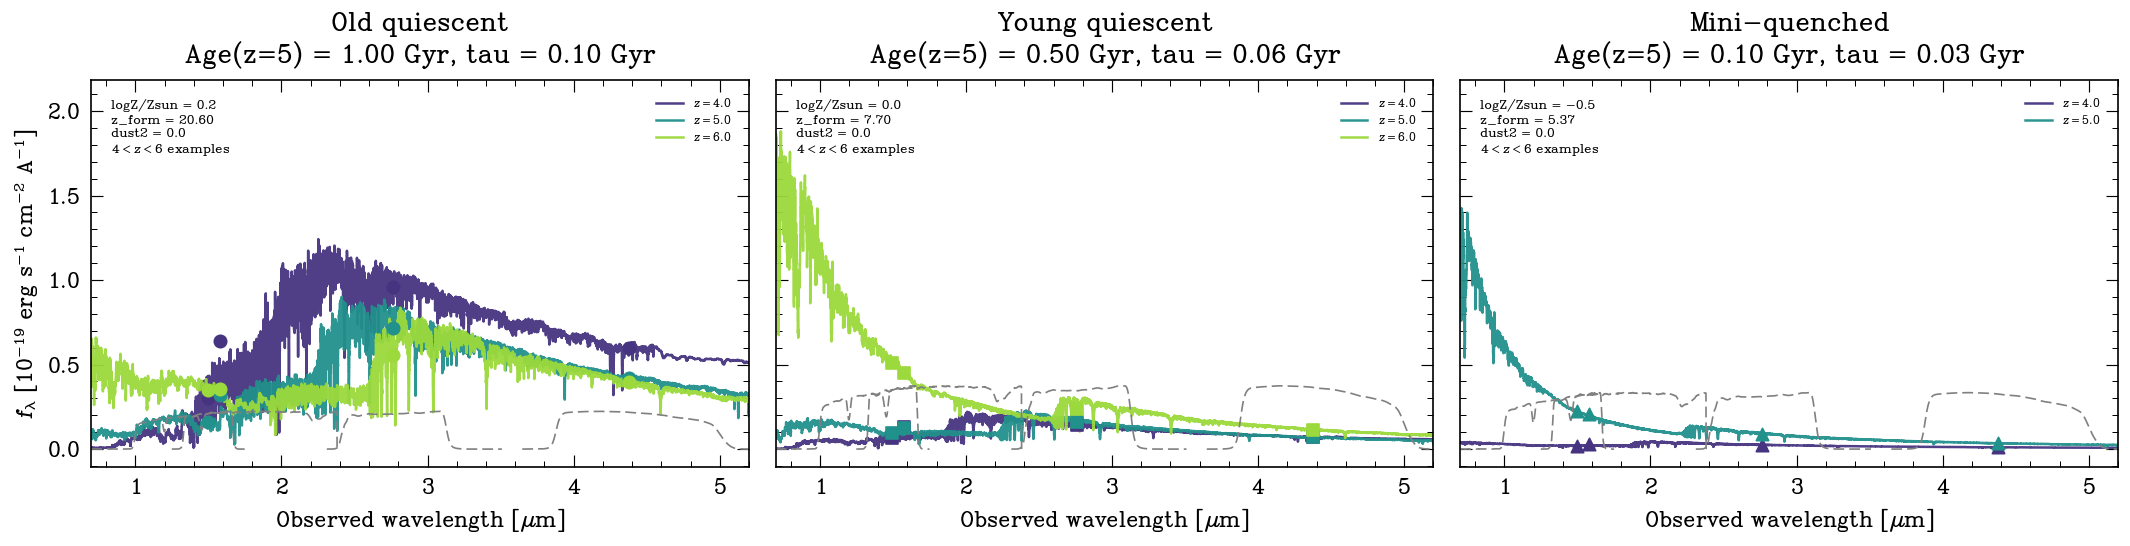

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
z_colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(EXAMPLE_REDSHIFTS)))

for ax, (model_name, model_products) in zip(axes, mock_sed_dict.items()):
    model_config = MODEL_CONFIGS[model_name]
    marker = PLOT_STYLES[model_name]["marker"]
    panel_max = max(np.nanmax(products["flux_obs_cgs_per_aa"] * 1e19) for products in model_products.values())

    for color, (key, products) in zip(z_colors, model_products.items()):
        wave_um = products["wave_obs_aa"] / 1e4
        flux_plot = products["flux_obs_cgs_per_aa"] * 1e19
        phot_wave_um = products["filter_wave_aa"] / 1e4
        phot_flux_plot = products["sed_f_lambda_cgs_per_aa"] * 1e19

        ax.step(wave_um, flux_plot, where="mid", color=color, lw=1.5, alpha=0.95,
                label=fr"$z={products['z_obs']:.1f}$")
        ax.scatter(phot_wave_um, phot_flux_plot, color=color, marker=marker, s=55, zorder=5)

    filter_scale = 0.18 * panel_max
    for band in filters:
        filt_wave_um = band.wavelength / 1e4
        filt_trans = band.transmission / np.nanmax(band.transmission)
        ax.plot(filt_wave_um, filt_trans * filter_scale, color="gray", ls="--", lw=1)

    ax.set_title(f"{model_config['label']}\nAge(z=5) = {model_config['age_at_reference_redshift_gyr']:.2f} Gyr, tau = {model_config['tau_gyr']:.2f} Gyr")
    ax.set_xlim(0.7, 5.2)
    ax.set_xlabel(r"Observed wavelength [$\mu$m]")
    ax.text(0.03, 0.95,
            f"logZ/Zsun = {model_config['logzsol']:.1f}\n"
            f"z_form = {model_config['formation_redshift']:.2f}\n"
            f"dust2 = {model_config['dust2']:.1f}\n"
            r"$4 < z < 6$ examples",
            transform=ax.transAxes, ha="left", va="top", fontsize=9)
    ax.legend(loc="upper right", frameon=False, fontsize=8)

axes[0].set_ylabel(r"$f_\lambda$ [$10^{-19}$ erg s$^{-1}$ cm$^{-2}$ A$^{-1}$]")

plt.tight_layout()


In [22]:
def plot_colour_colour_diagram(colour_mode, figsize=(7.0, 5.2)):
    fig, ax = plt.subplots(1, 1, figsize=figsize)

    colour_config = COLOUR_MODES[colour_mode]
    colour_track_dict = colour_tracks[colour_mode]

    for model_name, colour_track in colour_track_dict.items():
        color = PLOT_STYLES[model_name]["color"]
        marker = PLOT_STYLES[model_name]["marker"]
        label = MODEL_CONFIGS[model_name]["label"]

        ax.plot(colour_track["color_x"], colour_track["color_y"], color=color, lw=1.6, alpha=1.0, label=label)
        ax.scatter(colour_track["color_x"], colour_track["color_y"], color=color, s=18, alpha=0.5, zorder=2)

        for key, products in mock_sed_dict[model_name].items():
            x_colour = products["colors"][colour_mode]["x"]
            y_colour = products["colors"][colour_mode]["y"]
            ax.scatter(x_colour, y_colour, color=color, marker=marker, s=85, edgecolor="black", lw=0.6, zorder=5)
            ax.text(x_colour + 0.02, y_colour + 0.02, f"{products['z_obs']:.1f}", color=color, fontsize=8)

    x_min, x_max = 0.0, 3.2
    y_min, y_max = -0.2, 1.2
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    plot_long24_wedge(ax, LONG24_SHORT_WEDGE, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
                     label_prefix="Long+24", lw=2.4, ls="-")
    plot_long24_wedge(ax, LONG24_LONG_WEDGE, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
                         label_prefix="Long+24 (extended)", lw=1.8, ls="--")

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    x_anchor = xlim[0] + 0.1 * (xlim[1] - xlim[0])
    y_anchor = ylim[1] - 0.2 * (ylim[1] - ylim[0])

    for model_name, dust_vector in dust_vectors.items():
        color = PLOT_STYLES[model_name]["color"]
        x0 = dust_vector["dust_free"]["colors"][colour_mode]["x"]
        y0 = dust_vector["dust_free"]["colors"][colour_mode]["y"]
        x1 = dust_vector["dust_reddened"]["colors"][colour_mode]["x"]
        y1 = dust_vector["dust_reddened"]["colors"][colour_mode]["y"]
        dx = x1 - x0
        dy = y1 - y0

        # ax.annotate(
        #     "",
        #     xy=(x_anchor + dx, y_anchor + dy),
        #     xytext=(x_anchor, y_anchor),
        #     arrowprops=dict(arrowstyle="->", color=color, lw=2.0, shrinkA=0, shrinkB=0, mutation_scale=14),
        #     zorder=10,
        #     annotation_clip=False,
        # )
        
    ax.set_xlabel(f"{colour_config['x_label']} [AB mag]")
    ax.set_ylabel("F277W - F444W [AB mag]")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left", frameon=False)

    plt.tight_layout()

    return fig, ax

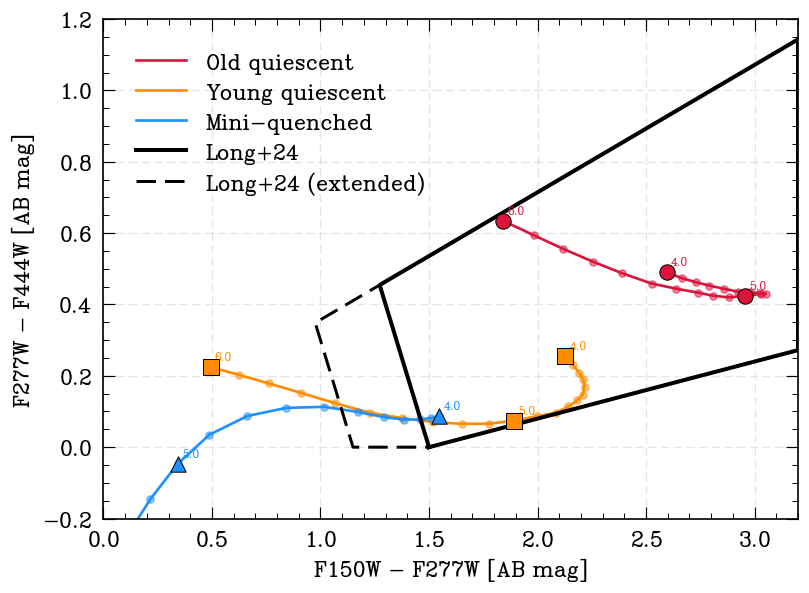

In [23]:
fig_f150w, ax_f150w = plot_colour_colour_diagram("f150w")

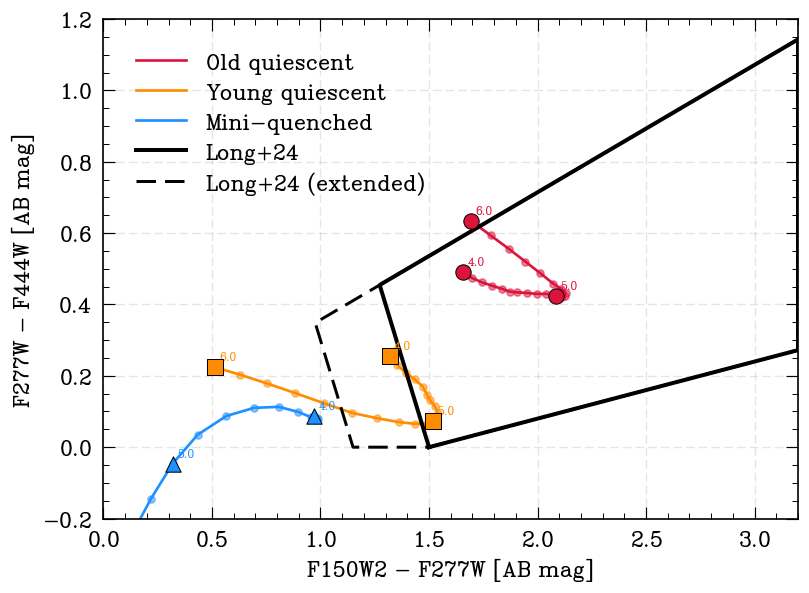

In [24]:
fig_f150w2, ax_f150w2 = plot_colour_colour_diagram("f150w2")